# Single-cell UMAPs for each cancer group

Computes a UMAP of subsampled single cells for each cancer group, and finds example cells to show next to the UMAP.

**Why:** the UMAP shows how single cells of the cell lines of one cancer group relate to each other, and the example cell images show what the different regions of the UMAP look like.

**Input:** `<plate>_sc_feature_selected.parquet` of every plate (multivariate).
Each plate has its own features, so the UMAPs use the features that all nine plates share.
The profiles of each plate are standardized to that plate.

**Subsampling:** at most `cells_per_line_per_plate` cells of each cell line on each plate are drawn at random, with a fixed seed, so a cell line with many cells does not dominate its UMAP.
All three time points are used, and the time point is saved with every cell.

**Example cells:** the cells of each cancer group are grouped into `n_clusters` clusters with k-means on the UMAP coordinates, and the cell closest to the center of each cluster is the example.
Its image is cut from the raw images with `pccma_utils.single_cells.crop_cells_as_png` (`utils/pccma_utils/`; raw images, no illumination correction, each channel stretched in its own crop).
The examples are a starting point: cells to point at in a figure can be chosen from `single_cell_umap_coordinates_by_cancer_group.parquet` and cut with the same function.

**Output:** in `results/3.single_cell_embedding/`
- `single_cell_umap_coordinates_by_cancer_group.parquet`: one row per sampled cell with the cell line, plate, well, site (field number), nucleus position in the image, time point, UMAP coordinates, cluster, and the cancer group and tissue site.
- `single_cell_umap_example_cells.parquet`: the example cell of each cluster (`selection` says how it was chosen), with its image as PNG bytes in the column `image_png` (draw it with `pccma_utils.single_cells.png_to_array`).

The notebook also shows the UMAPs of all cancer groups, and one cancer group next to its example cells; these views are displayed in the notebook and are not saved to disk.

## Import libraries

In [1]:
import pathlib
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import umap
from pccma_utils.cell_lines import load_cell_line_groups
from pccma_utils.profiles import numeric_features
from pccma_utils.single_cells import closest_to_centers, crop_cells_as_png, png_to_array, sample_cells
from sklearn.cluster import KMeans

# UMAP warns that a fixed random seed runs it on one thread, which is what keeps the embedding reproducible
warnings.filterwarnings("ignore", message="n_jobs value")

## Set paths and parameters

In [2]:
metadata_path = pathlib.Path("../cell_lines/pccma_cell_line_metadata.csv")
groups_path = pathlib.Path("../cell_lines/plotting_helpers/cancer_type_categories.yaml")

# single-cell feature-selected profiles and raw images: use the local data folder and fall back to the bandicoot mount
local_dir = pathlib.Path("../4.preprocess_features/data/single_cell_profiles")
bandicoot_root = pathlib.Path("~/mnt/bandicoot/PCCMA_data").expanduser()
profile_dir = local_dir if any(local_dir.glob("BR*_sc_feature_selected.parquet")) else bandicoot_root / "Atlas_v2_profiles/single_cell_profiles"
screen_dir = bandicoot_root / "Atlas_v2_screen"

results_dir = pathlib.Path("./results/3.single_cell_embedding")
results_dir.mkdir(parents=True, exist_ok=True)

cells_per_line_per_plate = 500  # cells drawn per cell line on each plate
n_clusters = 6  # clusters, and so example cells, per cancer group
crop_size = 160  # pixels of an example image (about 95 um)
umap_parameters = {"n_neighbors": 15, "min_dist": 0.1, "n_components": 2, "metric": "euclidean", "random_state": 0}
rng_seed = 0

## Features shared by all plates

In [3]:
plate_files = sorted(profile_dir.glob("BR*_sc_feature_selected.parquet"))

shared = set.intersection(*[numeric_features(pq.read_schema(file)) for file in plate_files])
features = sorted(shared)
print(f"{len(plate_files)} plates, {len(features)} features shared by all plates")

9 plates, 547 features shared by all plates


## Subsample the cells

In [4]:
cells_df, counts_df = sample_cells(plate_files, features, cells_per_line_per_plate, rng_seed)
for plate in counts_df.itertuples():
    print(f"{plate.plate_file}: {plate.sampled} of {plate.available} cells")
cells_df = cells_df.merge(
    load_cell_line_groups(metadata_path, groups_path)[["cell_line", "cancer_group", "tissue_site"]],
    left_on="Metadata_cell_line", right_on="cell_line", how="left",
).drop(columns="cell_line")
assert cells_df["cancer_group"].notna().all(), "a cell line has no cancer group"
print(f"{len(cells_df)} cells from {cells_df['Metadata_cell_line'].nunique()} cell lines in {cells_df['cancer_group'].nunique()} cancer groups")

BR00150695_sc_feature_selected.parquet: 6500 of 80493 cells
BR00150696_sc_feature_selected.parquet: 7000 of 95069 cells
BR00150697_sc_feature_selected.parquet: 7000 of 123089 cells
BR00150698_sc_feature_selected.parquet: 8500 of 123322 cells
BR00150699_sc_feature_selected.parquet: 8459 of 149197 cells
BR00150700_sc_feature_selected.parquet: 8500 of 186116 cells
BR00150701_sc_feature_selected.parquet: 12115 of 94105 cells
BR00150702_sc_feature_selected.parquet: 11941 of 129379 cells
BR00150703_sc_feature_selected.parquet: 11737 of 223942 cells
81752 cells from 54 cell lines in 13 cancer groups


## UMAP and clusters for each cancer group

The cluster number is stored with every cell and the example cell of each cluster is the one closest to its center.

In [5]:
cells_df["umap_1"], cells_df["umap_2"], cells_df["cluster"] = np.nan, np.nan, -1
example_index = []  # the example cell (closest to the center of its cluster) of every cluster

for group, group_df in cells_df.groupby("cancer_group"):
    embedding = umap.UMAP(**umap_parameters).fit_transform(group_df[features].to_numpy())
    cells_df.loc[group_df.index, ["umap_1", "umap_2"]] = embedding

    kmeans = KMeans(n_clusters=min(n_clusters, len(group_df)), n_init=10, random_state=rng_seed).fit(embedding)
    cells_df.loc[group_df.index, "cluster"] = kmeans.labels_ + 1
    closest = closest_to_centers(embedding, kmeans.labels_, kmeans.cluster_centers_)
    example_index.extend(group_df.index[closest["position"]])
    print(f"{group}: {group_df['Metadata_cell_line'].nunique()} cell lines, {len(group_df)} cells")

keep = ["Metadata_cell_line", "Metadata_Plate", "Metadata_Well", "Metadata_Site", "Metadata_time_point",
        "Metadata_Nuclei_Location_Center_X", "Metadata_Nuclei_Location_Center_Y", "cancer_group", "tissue_site",
        "umap_1", "umap_2", "cluster"]
cells_df[keep].to_parquet(results_dir / "single_cell_umap_coordinates_by_cancer_group.parquet", compression="zstd")

Atypical teratoid rhabdoid tumor: 1 cell lines, 1500 cells


Ependymoma: 1 cell lines, 1500 cells


Ewing sarcoma family: 8 cell lines, 12000 cells


Germ cell tumor: 1 cell lines, 1500 cells


Glioma: 4 cell lines, 5959 cells


Malignant rhabdoid tumor: 2 cell lines, 3000 cells


... (3 outputs left out)

Osteosarcoma: 4 cell lines, 8500 cells


Retinoblastoma: 4 cell lines, 5065 cells


Rhabdomyosarcoma: 7 cell lines, 9825 cells


Wilms tumor: 1 cell lines, 1500 cells


## Example cell images

Cut the image of the example cell of each cluster from the raw images of its plate.

In [6]:
examples_df = cells_df.loc[example_index, keep].reset_index(drop=True)
examples_df["selection"] = "closest to the center of its cluster"
examples_df["image_png"] = crop_cells_as_png(examples_df, screen_dir, crop_size)

examples_df.to_parquet(results_dir / "single_cell_umap_example_cells.parquet", compression="zstd", index=False)
print(f"{len(examples_df)} example cells saved, with their images")

78 example cells saved, with their images


## All cancer groups at a glance

The UMAP of every cancer group, colored by cell line.
The view is displayed here and not saved to disk.

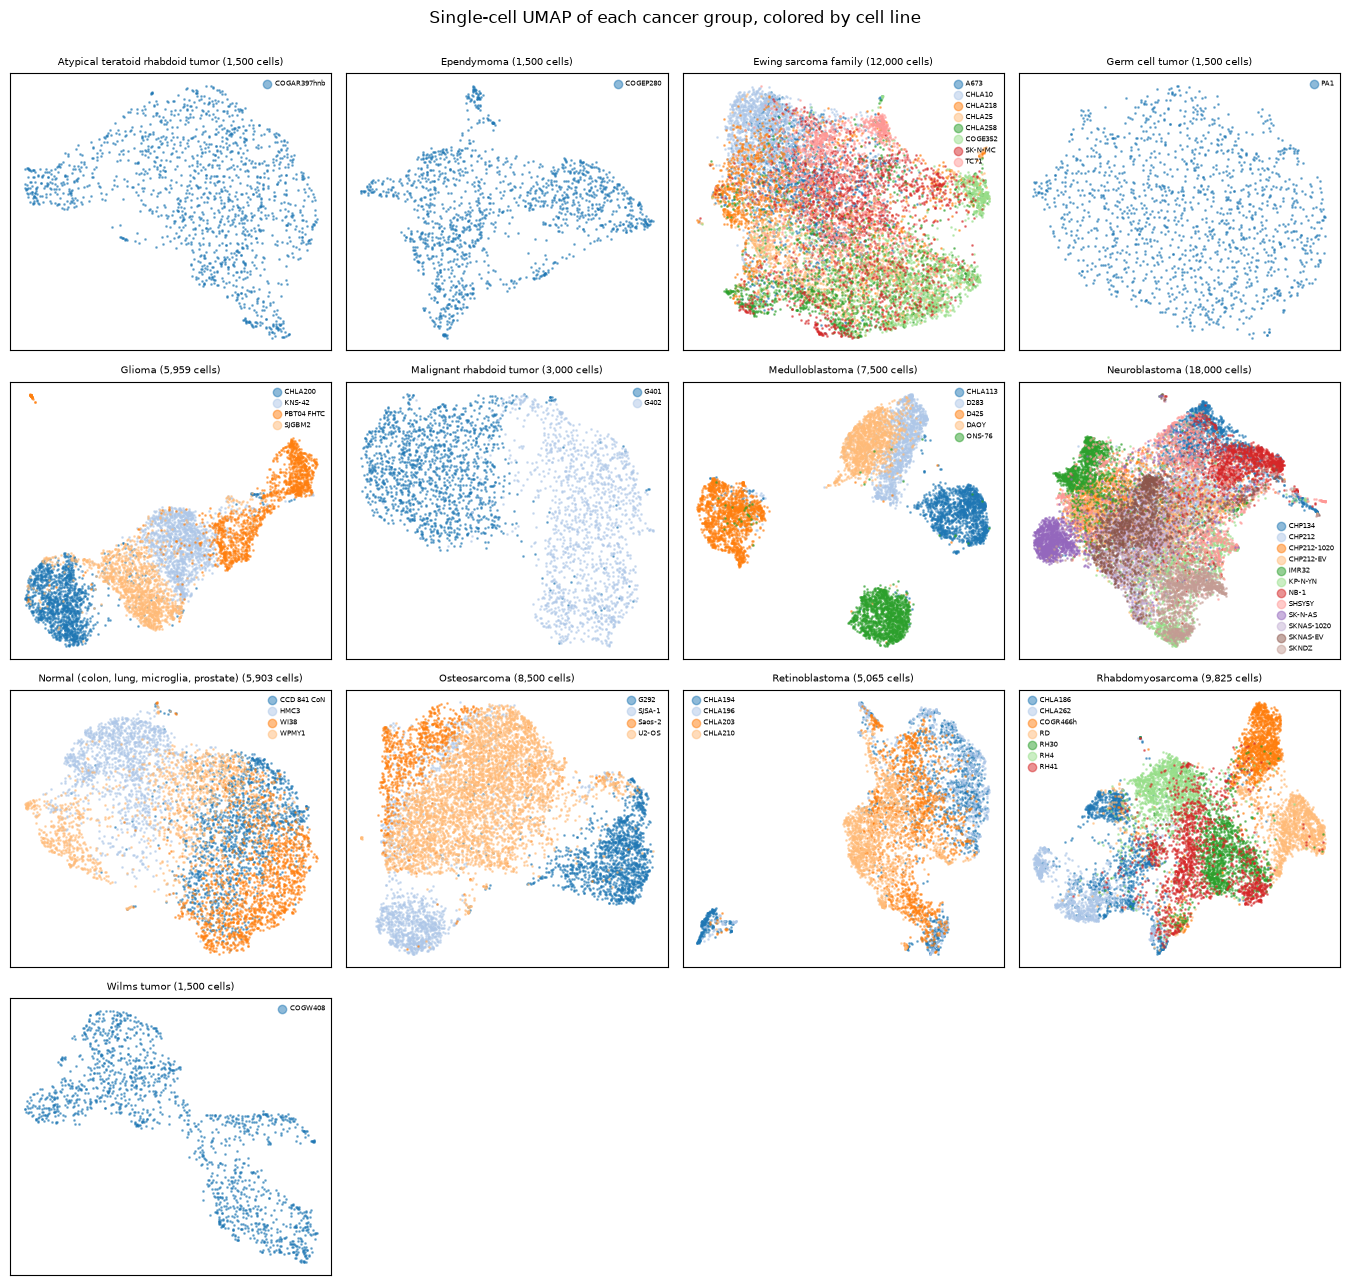

In [7]:
umap_df = pd.read_parquet(results_dir / "single_cell_umap_coordinates_by_cancer_group.parquet")

groups = sorted(umap_df["cancer_group"].unique())
n_columns = 4
n_rows = -(-len(groups) // n_columns)
fig, axes = plt.subplots(n_rows, n_columns, figsize=(3.4 * n_columns, 3.2 * n_rows), squeeze=False)
for ax, group in zip(axes.ravel(), groups):
    group_cells = umap_df[umap_df["cancer_group"] == group]
    for color, (line, line_cells) in zip(plt.get_cmap("tab20").colors, group_cells.groupby("Metadata_cell_line")):
        ax.scatter(line_cells["umap_1"], line_cells["umap_2"], s=1, alpha=0.5, color=color, label=line)
    ax.set_title(f"{group} ({len(group_cells):,} cells)", fontsize=7)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.legend(markerscale=6, fontsize=5, frameon=False, handletextpad=0.1)
for ax in axes.ravel()[len(groups):]:
    ax.axis("off")
fig.suptitle("Single-cell UMAP of each cancer group, colored by cell line", y=1.0)
fig.tight_layout()
plt.show()

## One cancer group at a glance

The UMAP of one cancer group colored by cluster, next to the example cell of each cluster (the cell closest to the center of the cluster).
Set `preview_group` to look at another cancer group.
The view is displayed here and not saved to disk.

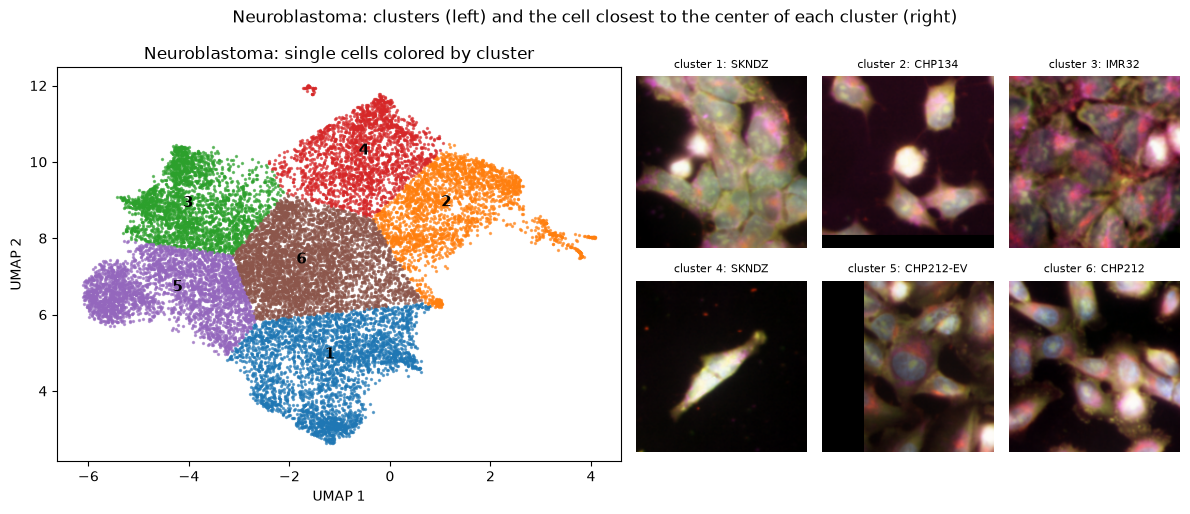

In [8]:
preview_group = "Neuroblastoma"

umap_df = pd.read_parquet(results_dir / "single_cell_umap_coordinates_by_cancer_group.parquet")
examples_df = pd.read_parquet(results_dir / "single_cell_umap_example_cells.parquet")
group_cells = umap_df[umap_df["cancer_group"] == preview_group]
group_examples = examples_df[examples_df["cancer_group"] == preview_group].sort_values("cluster")

fig = plt.figure(figsize=(12, 5.2))
grid = fig.add_gridspec(2, 5, width_ratios=[1.6, 1.6, 1, 1, 1])
umap_ax = fig.add_subplot(grid[:, :2])
for cluster, cluster_cells in group_cells.groupby("cluster"):
    umap_ax.scatter(cluster_cells["umap_1"], cluster_cells["umap_2"], s=2, alpha=0.6)
    umap_ax.annotate(cluster, cluster_cells[["umap_1", "umap_2"]].median(), fontsize=11, weight="bold", ha="center")
umap_ax.set(title=f"{preview_group}: single cells colored by cluster", xlabel="UMAP 1", ylabel="UMAP 2")

for position, example in enumerate(group_examples.itertuples()):
    ax = fig.add_subplot(grid[position // 3, 2 + position % 3])
    ax.imshow(png_to_array(example.image_png))
    ax.set_title(f"cluster {example.cluster}: {example.Metadata_cell_line}", fontsize=8)
    ax.axis("off")
fig.suptitle(f"{preview_group}: clusters (left) and the cell closest to the center of each cluster (right)")
fig.tight_layout()
plt.show()